# J2 El Mantaro — pronóstico de heladas (1–6 h) con nubosidad de Open-Meteo y tipo de helada (blanca/negra) según la humedad de hoja

**Qué añade este notebook al anterior (`el_mantaro_heladas_hoja.ipynb`)**

1. **Nubosidad de Open-Meteo** (total, baja, media y alta) como predictor. La nubosidad nocturna es el factor que más frena el enfriamiento radiativo, y era la información que le faltaba al modelo.
2. **Tipo de helada a partir del sensor de hoja.** El sensor (probablemente dieléctrico) detecta la escarcha:
   * **helada blanca**: durante las horas bajo 0 °C la hoja muestra señal de agua o hielo (hay deposición de escarcha);
   * **helada negra**: la temperatura baja de 0 °C pero la hoja **sigue seca**. El aire es tan seco que no se deposita escarcha y no hay calor latente que frene el enfriamiento. Suele ser **más dañina**: el tejido se congela por dentro y no se ve a simple vista.
3. **Pronóstico del tipo de helada** en dos etapas: `P(negra) = P(helada) × P(negra | helada)`.

**Fuente de nubosidad.** Usamos la *Historical Forecast API* de Open-Meteo, con el modelo `best_match`. Guarda los **pronósticos** archivados, no un reanálisis, así que se parece a lo que tendríamos disponible en operación. Advertencia: el archivo une las primeras horas de corridas sucesivas, de modo que el valor a *t+h* puede venir de una corrida emitida algo después de *t*. Por eso la evaluación es **ligeramente optimista** en la parte de nubosidad. En operación hay que usar la *Forecast API* (función al final del notebook).

**Validación**: igual que antes, validación cruzada dejando un año fuera (2022–2026) y bootstrap por noche.

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             mean_absolute_error, balanced_accuracy_score, confusion_matrix)
from sklearn.inspection import permutation_importance

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

BASE = Path.cwd()
while not (BASE / 'data').exists() and BASE != BASE.parent:
    BASE = BASE.parent
DATA = BASE / 'data' / 'processed'
EXT = BASE / 'data' / 'external'
OUT = BASE / 'resultados'; (OUT / 'modelos').mkdir(parents=True, exist_ok=True)

EST = 'j2_el_mantaro'
LAT, LON = -11.833526, -75.389548
UMBRALES = {'meteorologica': 0.0, 'agronomica': 2.0}
LEADS = list(range(1, 7))
HORAS_EMISION = list(range(15, 24)) + list(range(0, 8))
UMB_MOJADO = 10      # % sobre la línea base seca para considerar la hoja mojada
UMB_HIELO = 10       # % sobre la línea base: si la hoja no supera esto en las horas < 0 °C -> helada negra
P_ALERTA = 0.5
N_BOOT = 1000
SEED = 42
rng = np.random.default_rng(SEED)
NUB_COLS = ['cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high']

## 1. Nubosidad de Open-Meteo

In [2]:
URL_HIST = ('https://historical-forecast-api.open-meteo.com/v1/forecast?latitude={lat}&longitude={lon}'
            '&start_date={a}&end_date={b}&hourly=' + ','.join(NUB_COLS) + '&timezone=America%2FLima')

def descargar_nubosidad_hist(a, b, lat=LAT, lon=LON):
    j = json.load(urllib.request.urlopen(URL_HIST.format(lat=lat, lon=lon, a=a, b=b), timeout=120))
    df = pd.DataFrame(j['hourly']).rename(columns={'time': 'fecha'})
    df['fecha'] = pd.to_datetime(df['fecha'])
    return df.set_index('fecha')

CACHE = EXT / 'openmeteo_nubosidad_j2_el_mantaro.csv'
if CACHE.exists():
    NUB = pd.read_csv(CACHE, parse_dates=['fecha']).set_index('fecha')
else:
    NUB = pd.concat([descargar_nubosidad_hist(f'{y}-01-01', f'{y}-12-31') for y in range(2022, 2027)])
    NUB.reset_index().to_csv(CACHE, index=False)
print(NUB.index.min(), '->', NUB.index.max(), '| faltantes:', NUB.isna().sum().sum())
NUB.describe().round(1)

2022-03-01 00:00:00 -> 2026-10-31 23:00:00 | faltantes: 0


,cloud_cover,cloud_cover_low,cloud_cover_mid,cloud_cover_high
count,40944.0,40944.0,40944.0,40944.0
mean,66.5,27.3,32.9,48.9
std,37.1,33.2,33.7,43.3
min,0.0,0.0,0.0,0.0
25%,33.0,1.0,3.0,0.0
50%,85.0,13.0,21.0,47.0
75%,100.0,40.0,54.0,98.0
max,100.0,100.0,100.0,100.0


## 2. Datos de la estación y variables

In [3]:
meta = pd.read_csv(DATA / 'estaciones.csv').set_index('estacion')
REN = {'temperatura_media': 'T', 'temperatura_minima': 'Tmin', 'temperatura_maxima': 'Tmax',
       'punto_rocio_medio': 'Td', 'humedad_media': 'HR', 'velocidad_viento_medio_1h': 'viento',
       'velocidad_viento_maximo_1h': 'viento_max', 'precipitacion_acc_1h': 'pp',
       'radiacion_solar_media_1h': 'rad', 'rh_hoja_arriba_media_1h': 'arriba',
       'rh_hoja_bajo_media_1h': 'bajo', 'suelo_temperatura_5cm': 'Tsuelo5'}

def preparar(d):
    d = d.copy()
    if 'fecha' in d: d = d.set_index('fecha')
    d = d.rename(columns=REN)
    for c in REN.values():
        if c not in d: d[c] = np.nan
    return d[list(REN.values())].asfreq('h')

def var_meteo(d):
    X = pd.DataFrame(index=d.index)
    for c in ['T', 'Tmin', 'Tmax', 'Td', 'HR', 'viento', 'viento_max', 'rad', 'Tsuelo5']:
        X[c] = d[c]
    X['dep'] = d['T'] - d['Td']
    for k in (1, 3, 6):
        X[f'dT_{k}h'] = d['T'] - d['T'].shift(k)
    X['dTd_3h'] = d['Td'] - d['Td'].shift(3)
    X['dHR_3h'] = d['HR'] - d['HR'].shift(3)
    X['viento_3h'] = d['viento'].rolling(3, min_periods=2).mean()
    X['pp_3h'] = d['pp'].rolling(3, min_periods=1).sum()
    X['pp_24h'] = d['pp'].rolling(24, min_periods=12).sum()
    X['Tmax_12h'] = d['Tmax'].rolling(12, min_periods=8).max()
    X['amplitud_12h'] = X['Tmax_12h'] - d['T']
    X['Tmin_24h'] = d['Tmin'].rolling(24, min_periods=12).min()
    rad24 = d['rad'].rolling(24, min_periods=18).sum()
    X['claridad_24h'] = rad24 / rad24.rolling('60D', min_periods=24 * 20).quantile(.95)
    X['suelo_menos_aire'] = d['Tsuelo5'] - d['T']
    h, doy = d.index.hour, d.index.dayofyear
    X['hora_sin'], X['hora_cos'] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    X['doy_sin'], X['doy_cos'] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    return X

def linea_base_hoja(d):
    seco = d.index.hour.isin(range(11, 16)) & (d['pp'].fillna(0) == 0) & (d['HR'] < 60)
    rel = {}
    for k in ('arriba', 'bajo'):
        base = d[k].where(seco).rolling('30D', min_periods=20).median().shift(1).ffill()
        rel[k] = d[k] - base
    return rel

def var_hoja(d):
    X = pd.DataFrame(index=d.index)
    noche = (d.index - pd.Timedelta(hours=12)).normalize()
    rel = linea_base_hoja(d)
    for k in ('arriba', 'bajo'):
        r = rel[k]
        X[f'{k}_rel'] = r
        for L in (1, 3):
            X[f'{k}_d{L}h'] = r - r.shift(L)
        X[f'{k}_max3h'] = r.rolling(3, min_periods=2).max()
        moj = (r > UMB_MOJADO).astype(float).where(r.notna())
        X[f'{k}_horas_mojado'] = moj.fillna(0).groupby(noche).cumsum()
    X['arriba_menos_bajo'] = X['arriba_rel'] - X['bajo_rel']
    X['mojado_y_dep'] = X['arriba_rel'] / (1 + (d['T'] - d['Td']).clip(lower=0))
    return X

def var_nub(nub, idx, leads=LEADS):
    # nubosidad pronosticada en t y en las horas de validez t+1..t+6
    n = nub.reindex(idx)
    X = pd.DataFrame(index=idx)
    for c in NUB_COLS:
        X[f'{c}_t'] = n[c]
        fut = pd.concat([n[c].shift(-k) for k in leads], axis=1)
        X[f'{c}_med6h'] = fut.mean(axis=1)
        X[f'{c}_min6h'] = fut.min(axis=1)
    for k in leads:
        X[f'cc_t+{k}'] = n['cloud_cover'].shift(-k)
        X[f'ccl_t+{k}'] = n['cloud_cover_low'].shift(-k)
    X['cc_tendencia'] = n['cloud_cover'].shift(-6) - n['cloud_cover']
    X['cc_previa_6h'] = n['cloud_cover'].rolling(6, min_periods=3).mean()
    return X

D = preparar(pd.read_csv(DATA / 'horario' / f'{EST}.csv', parse_dates=['fecha']))
XM, XH, XN = var_meteo(D), var_hoja(D), var_nub(NUB, D.index)
F_METEO, F_HOJA, F_NUB = list(XM.columns), list(XH.columns), list(XN.columns)
ALL = XM.join(XH).join(XN)
for k in LEADS:
    ALL[f'y_T_{k}'] = D['Tmin'].shift(-k)
ALL['y_T_alerta6'] = pd.concat([D['Tmin'].shift(-k) for k in LEADS], axis=1).min(axis=1, skipna=False)
ALL['noche'] = (D.index - pd.Timedelta(hours=12)).normalize()
ALL['anio'] = D.index.year
print(len(F_METEO), 'meteo |', len(F_HOJA), 'hoja |', len(F_NUB), 'nubosidad')

27 meteo | 12 hoja | 26 nubosidad


### 2.1 Nubosidad frente a enfriamiento nocturno

Comprobación física: con la nubosidad alta la noche debería enfriarse mucho menos.

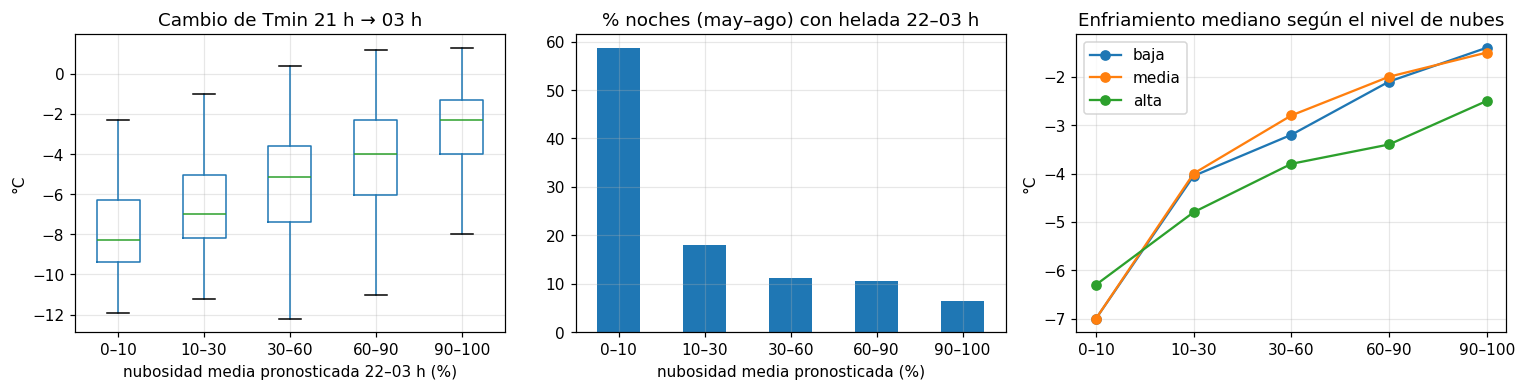

In [4]:
n21 = ALL[(ALL.index.hour == 21) & ALL['y_T_6'].notna()].copy()
n21['enfr_6h'] = n21['y_T_6'] - n21['Tmin']
n21['cc_clase'] = pd.cut(n21['cloud_cover_med6h'], [-1, 10, 30, 60, 90, 101], labels=['0–10', '10–30', '30–60', '60–90', '90–100'])
n21['helada6'] = n21['y_T_alerta6'] <= 0
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
n21.boxplot(column='enfr_6h', by='cc_clase', ax=axs[0], showfliers=False)
axs[0].set_title('Cambio de Tmin 21 h → 03 h'); axs[0].set_xlabel('nubosidad media pronosticada 22–03 h (%)'); axs[0].set_ylabel('°C')
fr = n21[n21.index.month.isin(range(5, 9))].groupby('cc_clase', observed=True)['helada6'].mean() * 100
fr.plot.bar(ax=axs[1], rot=0, color='tab:blue'); axs[1].set_title('% noches (may–ago) con helada 22–03 h')
axs[1].set_xlabel('nubosidad media pronosticada (%)')
for c, lab in [('cloud_cover_low_med6h', 'baja'), ('cloud_cover_mid_med6h', 'media'), ('cloud_cover_high_med6h', 'alta')]:
    g = n21.groupby(pd.cut(n21[c], [-1, 10, 30, 60, 90, 101]), observed=True)['enfr_6h'].median()
    axs[2].plot(range(len(g)), g.values, 'o-', label=lab)
axs[2].set_xticks(range(5), ['0–10', '10–30', '30–60', '60–90', '90–100']); axs[2].legend()
axs[2].set_title('Enfriamiento mediano según el nivel de nubes'); axs[2].set_ylabel('°C')
plt.suptitle(''); plt.tight_layout(); plt.show()

## 3. Helada blanca o negra según la humedad de hoja

Para cada noche con helada (`Tmin ≤ 0 °C` entre 18 y 08 h) tomamos la **señal máxima de la hoja**, la mayor entre las caras arriba y bajo y relativa a la línea base seca, durante las horas bajo 0 °C:

* **blanca** si la señal máxima es ≥ `UMB_HIELO` (el sensor detectó escarcha);
* **negra** si no la supera (superficie seca durante toda la helada);
* **sin dato** si no hay lectura de hoja en las horas de helada.

Comparamos esta clasificación con la heurística del punto de rocío que usamos en el primer notebook (Td ≤ 0 y T−Td ≤ 3 °C en el mínimo).

In [5]:
REL = linea_base_hoja(D)
noche_s = ALL['noche']
h = D.index.hour
es_noche = (h >= 18) | (h <= 8)
fh = D[es_noche & (D['Tmin'] <= 0)].copy()
fh['senal'] = pd.concat([REL['arriba'], REL['bajo']], axis=1).max(axis=1).reindex(fh.index)
fh['noche'] = noche_s.reindex(fh.index)
fh['dep'] = fh['T'] - fh['Td']
NOCH = fh.groupby('noche').agg(horas_bajo0=('Tmin', 'size'), tmin=('Tmin', 'min'), senal_max=('senal', 'max'),
                               senal_med=('senal', 'median'), dep_med=('dep', 'median'), hr_max=('HR', 'max'),
                               td_min=('Td', 'min'), viento=('viento', 'mean'))
nub_noche = NUB.reindex(D.index[es_noche]).groupby(noche_s.reindex(D.index[es_noche])).mean()
NOCH = NOCH.join(nub_noche)
NOCH['tipo_hoja'] = np.select([NOCH['senal_max'].isna(), NOCH['senal_max'] >= UMB_HIELO], ['sin dato', 'blanca'], 'negra')
# heurística de Td (primer notebook), en la hora de la Tmin
idx_min = fh.groupby('noche')['Tmin'].idxmin()
td_m, dep_m = D.loc[idx_min.values, 'Td'].values, (D['T'] - D['Td']).loc[idx_min.values].values
NOCH['tipo_td'] = np.where((td_m <= 0) & (dep_m <= 3), 'blanca', 'negra')
NOCH.reset_index().to_csv(OUT / 'el_mantaro_tipo_helada.csv', index=False)
print(NOCH['tipo_hoja'].value_counts())
pd.crosstab(NOCH['tipo_hoja'], NOCH['tipo_td'], margins=True)

tipo_hoja
blanca    244
negra      24
Name: count, dtype: int64


tipo_td,blanca,negra,All
tipo_hoja,,,
blanca,229,15,244
negra,16,8,24
All,245,23,268


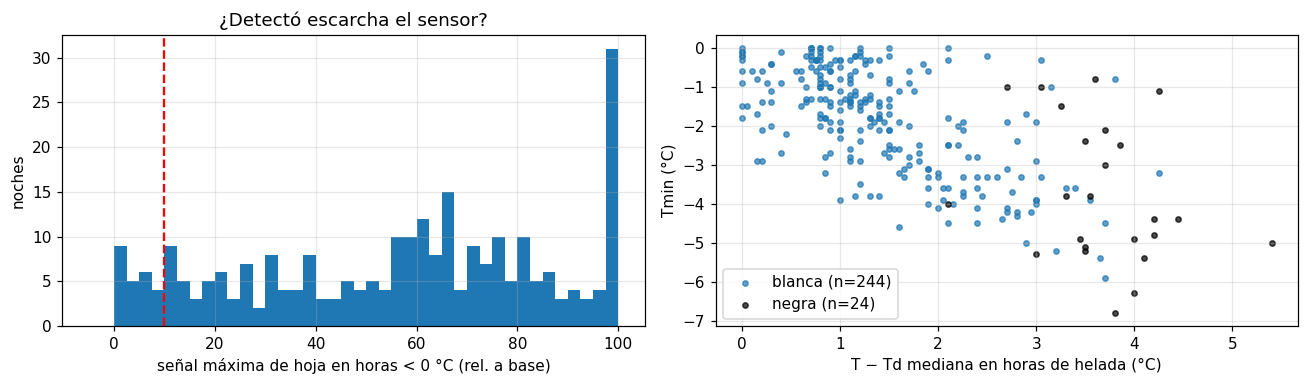

,tmin,horas_bajo0,dep_med,hr_max,td_min,viento,cloud_cover,cloud_cover_low
tipo_hoja,,,,,,,,
blanca,-1.6,5.0,1.2,93.0,-1.9,0.2,13.7,2.8
negra,-4.2,8.0,3.6,81.0,-6.2,0.2,8.5,0.0


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
NOCH['senal_max'].clip(-5, 100).hist(bins=np.arange(-5, 101, 2.5), ax=axs[0])
axs[0].axvline(UMB_HIELO, color='r', ls='--'); axs[0].set_xlabel('señal máxima de hoja en horas < 0 °C (rel. a base)')
axs[0].set_ylabel('noches'); axs[0].set_title('¿Detectó escarcha el sensor?')
v = NOCH[NOCH.tipo_hoja != 'sin dato']
for t, c in [('blanca', 'tab:blue'), ('negra', 'k')]:
    s = v[v.tipo_hoja == t]
    axs[1].scatter(s['dep_med'], s['tmin'], s=12, color=c, label=f'{t} (n={len(s)})', alpha=.7)
axs[1].set_xlabel('T − Td mediana en horas de helada (°C)'); axs[1].set_ylabel('Tmin (°C)'); axs[1].legend()
plt.tight_layout(); plt.show()
NOCH[NOCH.tipo_hoja != 'sin dato'].groupby('tipo_hoja')[
    ['tmin', 'horas_bajo0', 'dep_med', 'hr_max', 'td_min', 'viento', 'cloud_cover', 'cloud_cover_low']].median().round(1)

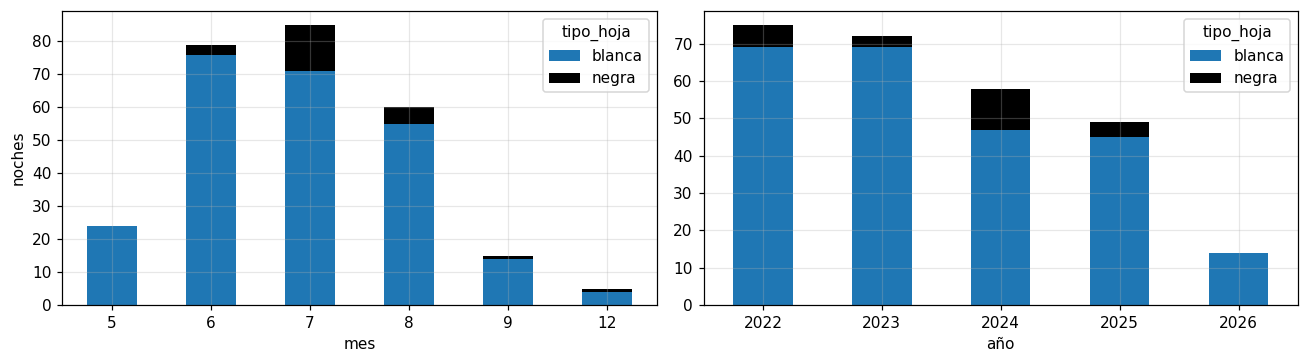

In [7]:
# Distribución mensual y anual de los tipos
v = NOCH[NOCH.tipo_hoja != 'sin dato']
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
pd.crosstab(v.index.month, v.tipo_hoja).plot.bar(ax=axs[0], stacked=True, rot=0, color=['tab:blue', 'k'])
axs[0].set_xlabel('mes'); axs[0].set_ylabel('noches')
pd.crosstab(v.index.year, v.tipo_hoja).plot.bar(ax=axs[1], stacked=True, rot=0, color=['tab:blue', 'k'])
axs[1].set_xlabel('año'); plt.tight_layout(); plt.show()

## 4. Pronóstico de helada (1–6 h): ¿aporta la nubosidad?

Cuatro variantes con el mismo clasificador y la misma muestra:

| variante | predictores |
|---|---|
| base | meteorología de la estación |
| + hoja | base + humedad de hoja construida |
| + nubosidad | base + nubosidad de Open-Meteo |
| + hoja + nubosidad | todo |

In [8]:
MUESTRA = ALL[ALL.index.hour.isin(HORAS_EMISION) & ALL['T'].notna() & ALL['Tmin'].notna()
              & ALL['arriba_rel'].notna() & ALL['bajo_rel'].notna() & ALL['cloud_cover_t'].notna()].copy()
VARIANTES = {'base': F_METEO, '+ hoja': F_METEO + F_HOJA, '+ nubosidad': F_METEO + F_NUB,
             '+ hoja + nubosidad': F_METEO + F_HOJA + F_NUB}
ANIOS = sorted(MUESTRA['anio'].unique())
print(len(MUESTRA), 'horas de emisión; años', ANIOS)

def clf(**kw):
    return HistGradientBoostingClassifier(max_iter=500, learning_rate=0.04, max_leaf_nodes=31, min_samples_leaf=40,
                                          l2_regularization=1.0, early_stopping=True, validation_fraction=0.15,
                                          random_state=SEED, **kw)
def reg():
    return HistGradientBoostingRegressor(max_iter=500, learning_rate=0.04, max_leaf_nodes=31, min_samples_leaf=40,
                                         l2_regularization=1.0, early_stopping=True, validation_fraction=0.15,
                                         random_state=SEED)

OOF = {}
for nom_u, u in UMBRALES.items():
    for lead in [*LEADS, 'alerta6']:
        col = f'y_T_{lead}'
        sub = MUESTRA[MUESTRA[col].notna()]
        res = sub[['noche', 'anio', 'Tmin', col]].copy()
        res['y'] = sub[col] <= u
        res['inicio'] = sub['Tmin'] > u
        for a in ANIOS:
            tr, te = sub['anio'] != a, sub['anio'] == a
            for v, fs in VARIANTES.items():
                res.loc[te, f'p_{v}'] = clf().fit(sub.loc[tr, fs], res.loc[tr, 'y']).predict_proba(sub.loc[te, fs])[:, 1]
            if nom_u == 'meteorologica' and lead != 'alerta6':
                for v in ('base', '+ hoja + nubosidad'):
                    res.loc[te, f'T_{v}'] = reg().fit(sub.loc[tr, VARIANTES[v]], sub.loc[tr, col]).predict(sub.loc[te, VARIANTES[v]])
        OOF[(nom_u, lead)] = res
    print('listo:', nom_u)

26451 horas de emisión; años [2022, 2023, 2024, 2025, 2026]


listo: meteorologica


listo: agronomica


In [9]:
def csi(y, yh):
    a = (y & yh).sum(); b = (~y & yh).sum(); c = (y & ~yh).sum()
    return a / max(a + c, 1), b / max(a + b, 1), a / max(a + b + c, 1)

filas = []
for (nom_u, lead), res in OOF.items():
    for casos in ('todos', 'inicio'):
        t = res if casos == 'todos' else res[res['inicio']]
        y = t['y'].values
        if y.sum() < 10: continue
        bsc = brier_score_loss(y, np.full(len(y), y.mean()))
        for v in VARIANTES:
            p = t[f'p_{v}'].values
            pod, far, c = csi(y, p >= P_ALERTA)
            filas.append({'umbral': nom_u, 'plazo': lead, 'casos': casos, 'variante': v, 'n_eventos': int(y.sum()),
                          'AP': average_precision_score(y, p), 'BSS': 1 - brier_score_loss(y, p) / bsc,
                          'POD': pod, 'FAR': far, 'CSI': c})
MET = pd.DataFrame(filas)
MET.to_csv(OUT / 'el_mantaro_nubosidad_metricas.csv', index=False)
MET[MET.plazo.isin([1, 3, 6, 'alerta6'])].pivot_table(
    index=['umbral', 'casos', 'plazo'], columns='variante', values=['BSS', 'CSI'], sort=False)[
    [(m, v) for m in ('BSS', 'CSI') for v in VARIANTES]].round(3)

BSS                                          CSI                                      
variante                       base + hoja + nubosidad + hoja + nubosidad   base + hoja + nubosidad + hoja + nubosidad
umbral        casos  plazo                                                                                            
meteorologica todos  1        0.911  0.912       0.910              0.911  0.896  0.894       0.890              0.889
                     3        0.819  0.816       0.827              0.828  0.791  0.785       0.792              0.793
                     6        0.711  0.712       0.740              0.743  0.674  0.680       0.709              0.712
                     alerta6  0.770  0.772       0.791              0.792  0.752  0.751       0.777              0.778
              inicio 1        0.637  0.641       0.631              0.637  0.598  0.591       0.575              0.571
                     3        0.706  0.704       0.724              0.727  0.666  0.661       0.674              0.676
                     6        0.676  0.678       0.710              0.714  0.639  0.648       0.677              0.684
                     alerta6  0.644  0.646       0.675              0.676  0.623  0.620       0.658              0.657
agronomica    todos  1        0.899  0.898       0.901              0.901  0.882  0.881       0.885              0.887
                     3        0.771  0.770       0.792              0.790  0.750  0.750       0.774              0.777
                     6        0.675  0.675       0.716              0.717  0.662  0.659       0.696              0.694
                     alerta6  0.744  0.743       0.772              0.772  0.751  0.750       0.774              0.774
              inicio 1        0.586  0.579       0.594              0.595  0.542  0.535       0.560              0.560
                     3        0.612  0.608       0.654              0.649  0.582  0.584       0.632              0.635
                     6        0.616  0.616       0.665              0.666  0.605  0.602       0.645              0.643
                     alerta6  0.599  0.597       0.646              0.645  0.604  0.602       0.638              0.639

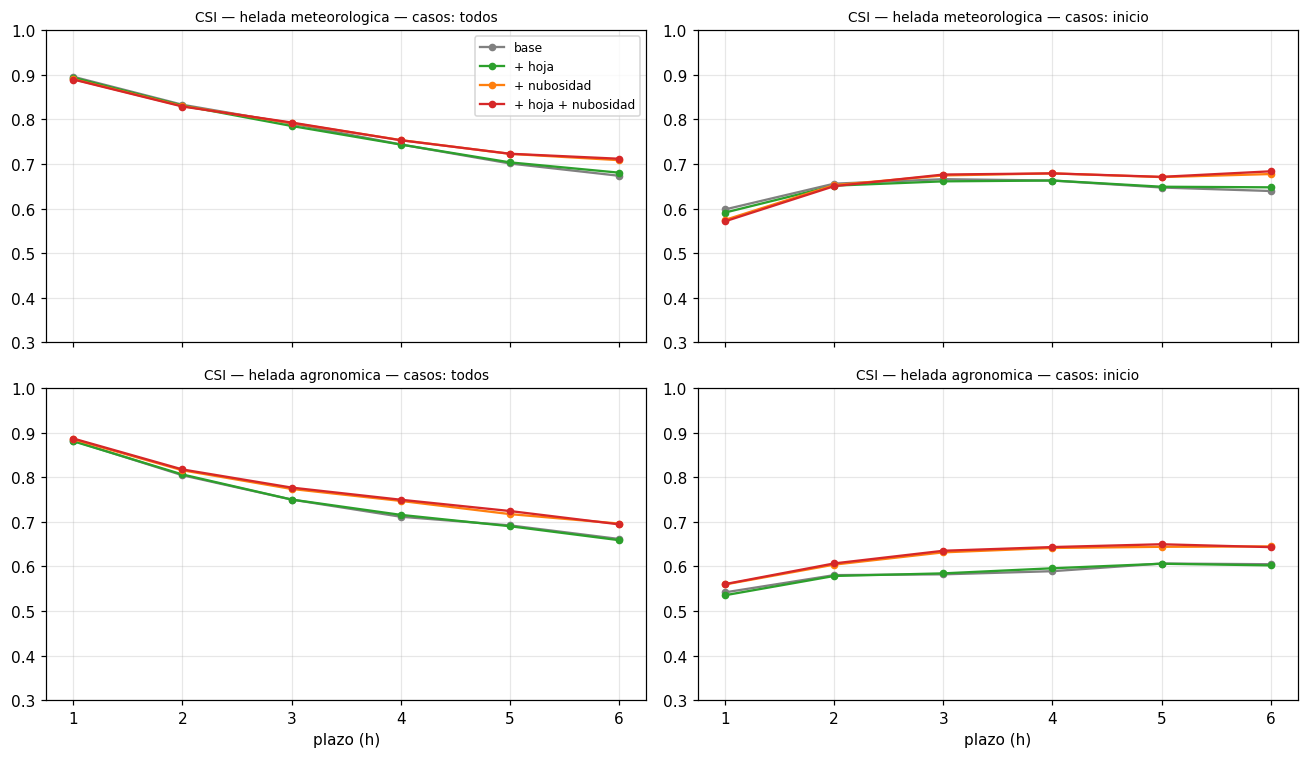

In [10]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
cols = dict(zip(VARIANTES, ['0.5', 'tab:green', 'tab:orange', 'tab:red']))
for i, nom_u in enumerate(UMBRALES):
    for j, casos in enumerate(['todos', 'inicio']):
        ax = axs[i, j]
        g = MET[(MET.umbral == nom_u) & (MET.casos == casos) & (MET.plazo != 'alerta6')]
        for v in VARIANTES:
            gv = g[g.variante == v]
            ax.plot(gv['plazo'].astype(int), gv['CSI'], 'o-', ms=4, color=cols[v], label=v)
        ax.set_title(f'CSI — helada {nom_u} — casos: {casos}', fontsize=9); ax.set_ylim(0.3, 1)
for ax in axs[-1]: ax.set_xlabel('plazo (h)')
axs[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 4.1 Bootstrap por noche: mejora respecto de la variante *base*

In [11]:
def boot_diff(res, va, vb='base', casos='todos'):
    t = res if casos == 'todos' else res[res['inicio']]
    y = t['y'].astype(float)
    cols = {'n': 1.0, 'y': y, 'se_a': (t[f'p_{va}'] - y) ** 2, 'se_b': (t[f'p_{vb}'] - y) ** 2}
    for s, v in (('a', va), ('b', vb)):
        al = t[f'p_{v}'] >= P_ALERTA
        cols[f'h_{s}'], cols[f'f_{s}'], cols[f'm_{s}'] = t['y'] & al, ~t['y'] & al, t['y'] & ~al
    g = pd.DataFrame(cols, index=t.index).astype(float).groupby(t['noche']).sum()
    S = pd.DataFrame(rng.multinomial(len(g), np.ones(len(g)) / len(g), size=N_BOOT) @ g.values, columns=g.columns)
    clim = S['y'] / S['n']; bsc = (S['y'] * (1 - clim) ** 2 + (S['n'] - S['y']) * clim ** 2) / S['n']
    dbss = (S['se_b'] - S['se_a']) / S['n'] / bsc
    dcsi = S['h_a'] / (S['h_a'] + S['f_a'] + S['m_a']) - S['h_b'] / (S['h_b'] + S['f_b'] + S['m_b'])
    return dbss, dcsi

ic = lambda s: f'{s.median():+.3f} [{s.quantile(.025):+.3f}, {s.quantile(.975):+.3f}]'
filas = []
for (nom_u, lead), res in OOF.items():
    for casos in ('todos', 'inicio'):
        for v in ('+ hoja', '+ nubosidad', '+ hoja + nubosidad'):
            dbss, dcsi = boot_diff(res, v, casos=casos)
            filas.append({'umbral': nom_u, 'plazo': lead, 'casos': casos, 'variante': v,
                          'ΔBSS': ic(dbss), 'ΔCSI': ic(dcsi),
                          'sig_BSS': dbss.quantile(.025) > 0, 'sig_CSI': dcsi.quantile(.025) > 0})
BOOT = pd.DataFrame(filas)
BOOT.to_csv(OUT / 'el_mantaro_nubosidad_bootstrap.csv', index=False)
BOOT[BOOT.casos == 'todos'].pivot_table(index=['umbral', 'plazo'], columns='variante', values='ΔBSS', aggfunc='first', sort=False)

variante                                + hoja              + nubosidad       + hoja + nubosidad
umbral        plazo                                                                             
meteorologica 1        +0.001 [-0.002, +0.004]  -0.001 [-0.005, +0.003]  -0.001 [-0.005, +0.004]
              2        -0.001 [-0.005, +0.002]  +0.001 [-0.005, +0.007]  +0.001 [-0.006, +0.008]
              3        -0.003 [-0.006, +0.001]  +0.009 [-0.000, +0.019]  +0.009 [+0.001, +0.019]
              4        +0.003 [-0.001, +0.007]  +0.018 [+0.006, +0.031]  +0.019 [+0.007, +0.031]
              5        +0.003 [-0.002, +0.008]  +0.016 [+0.001, +0.031]  +0.020 [+0.004, +0.036]
              6        +0.001 [-0.004, +0.007]  +0.029 [+0.011, +0.048]  +0.032 [+0.015, +0.053]
              alerta6  +0.002 [-0.002, +0.008]  +0.020 [+0.006, +0.036]  +0.022 [+0.008, +0.037]
agronomica    1        -0.002 [-0.004, -0.000]  +0.001 [-0.002, +0.005]  +0.001 [-0.002, +0.005]
              2        +0.000 [-0.002, +0.003]  +0.009 [+0.002, +0.016]  +0.009 [+0.001, +0.015]
              3        -0.002 [-0.004, +0.001]  +0.021 [+0.011, +0.033]  +0.019 [+0.009, +0.029]
              4        +0.000 [-0.003, +0.004]  +0.028 [+0.016, +0.041]  +0.029 [+0.016, +0.042]
              5        +0.003 [-0.002, +0.007]  +0.033 [+0.018, +0.049]  +0.035 [+0.019, +0.051]
              6        +0.000 [-0.004, +0.005]  +0.041 [+0.025, +0.058]  +0.042 [+0.022, +0.060]
              alerta6  -0.000 [-0.004, +0.003]  +0.028 [+0.015, +0.043]  +0.028 [+0.014, +0.043]

In [12]:
BOOT[BOOT.casos == 'inicio'].pivot_table(index=['umbral', 'plazo'], columns='variante', values='ΔCSI', aggfunc='first', sort=False)

variante                                + hoja              + nubosidad       + hoja + nubosidad
umbral        plazo                                                                             
meteorologica 1        -0.007 [-0.031, +0.015]  -0.024 [-0.051, +0.003]  -0.028 [-0.061, +0.006]
              2        -0.004 [-0.023, +0.015]  -0.003 [-0.028, +0.019]  -0.006 [-0.031, +0.020]
              3        -0.005 [-0.020, +0.010]  +0.008 [-0.014, +0.029]  +0.010 [-0.013, +0.032]
              4        +0.000 [-0.011, +0.011]  +0.016 [-0.006, +0.039]  +0.016 [-0.007, +0.037]
              5        +0.002 [-0.011, +0.013]  +0.023 [-0.000, +0.049]  +0.024 [+0.001, +0.047]
              6        +0.008 [-0.001, +0.018]  +0.039 [+0.017, +0.061]  +0.044 [+0.020, +0.068]
              alerta6  -0.003 [-0.015, +0.009]  +0.035 [+0.013, +0.056]  +0.034 [+0.011, +0.057]
agronomica    1        -0.007 [-0.025, +0.013]  +0.018 [-0.009, +0.047]  +0.019 [-0.010, +0.047]
              2        -0.002 [-0.014, +0.010]  +0.023 [-0.001, +0.047]  +0.026 [+0.004, +0.050]
              3        +0.002 [-0.009, +0.012]  +0.050 [+0.030, +0.070]  +0.053 [+0.033, +0.074]
              4        +0.006 [-0.003, +0.016]  +0.052 [+0.032, +0.073]  +0.053 [+0.034, +0.075]
              5        -0.000 [-0.009, +0.009]  +0.037 [+0.016, +0.059]  +0.043 [+0.022, +0.066]
              6        -0.003 [-0.012, +0.006]  +0.039 [+0.020, +0.058]  +0.039 [+0.019, +0.058]
              alerta6  -0.002 [-0.011, +0.006]  +0.033 [+0.014, +0.052]  +0.035 [+0.015, +0.054]

### 4.2 Error de la Tmin pronosticada

In [13]:
filas = []
for lead in LEADS:
    res = OOF[('meteorologica', lead)]; y = res[f'y_T_{lead}']
    for casos, m in [('todos', y.notna()), ('noches frías (Tmin ≤ 3 °C)', y <= 3)]:
        filas.append({'plazo': lead, 'casos': casos,
                      'MAE base': mean_absolute_error(y[m], res.loc[m, 'T_base']),
                      'MAE hoja+nub': mean_absolute_error(y[m], res.loc[m, 'T_+ hoja + nubosidad']),
                      'sesgo base': (res.loc[m, 'T_base'] - y[m]).mean(),
                      'sesgo hoja+nub': (res.loc[m, 'T_+ hoja + nubosidad'] - y[m]).mean()})
pd.DataFrame(filas).round(2)

,plazo,casos,MAE base,MAE hoja+nub,sesgo base,sesgo hoja+nub
0,1,todos,0.60,0.59,-0.01,-0.00
1,1,noches frías (Tmin ≤ 3 °C),0.36,0.36,0.15,0.14
2,2,todos,0.89,0.86,-0.02,-0.02
3,2,noches frías (Tmin ≤ 3 °C),0.59,0.58,0.35,0.33
4,3,todos,1.05,0.99,-0.01,-0.01
5,3,noches frías (Tmin ≤ 3 °C),0.83,0.78,0.60,0.53
6,4,todos,1.14,1.06,-0.01,-0.01
7,4,noches frías (Tmin ≤ 3 °C),1.01,0.92,0.76,0.63
8,5,todos,1.21,1.11,-0.01,-0.01
9,5,noches frías (Tmin ≤ 3 °C),1.15,1.03,0.89,0.75


## 5. Pronóstico del tipo de helada: ¿será negra?

**Etapa 2**: entre las horas de emisión en que **sí habrá helada** en *t+h*, según la etiqueta del sensor de hoja para esa noche, entrenamos un clasificador de `P(negra | helada)`. Como las heladas negras son pocas, usamos `class_weight='balanced'` y lo evaluamos con **AUC** y **exactitud balanceada**, dejando un año fuera.

Referencia: la regla del punto de rocío aplicada en la hora de emisión (negra si T−Td > 3 °C o Td > 0 °C en *t*). Ese es el criterio que usaríamos sin sensor de hoja.

**Probabilidad final**: `P(helada negra en t+h) = P(helada) × P(negra | helada)`.

In [14]:
TIPO = NOCH['tipo_hoja'].to_dict()
F_TIPO = F_METEO + F_HOJA + F_NUB

def clf_tipo():
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20,
                                          l2_regularization=2.0, class_weight='balanced', random_state=SEED)

OOF_T, MT = {}, []
for lead in [*LEADS, 'alerta6']:
    col = f'y_T_{lead}'
    sub = MUESTRA[MUESTRA[col] <= 0].copy()
    # noche a la que pertenece la hora de la helada (para alerta6, la propia noche de emisión)
    h_obj = sub.index + pd.Timedelta(hours=6 if lead == 'alerta6' else lead)
    sub['noche_obj'] = (h_obj - pd.Timedelta(hours=12)).normalize()
    sub['tipo'] = sub['noche_obj'].map(TIPO)
    sub = sub[sub['tipo'].isin(['blanca', 'negra'])]
    sub['y_negra'] = sub['tipo'] == 'negra'
    sub['p_negra'] = np.nan
    for a in ANIOS:
        tr, te = sub['anio'] != a, sub['anio'] == a
        if te.sum() == 0 or sub.loc[tr, 'y_negra'].sum() < 5: continue
        m = clf_tipo().fit(sub.loc[tr, F_TIPO], sub.loc[tr, 'y_negra'])
        sub.loc[te, 'p_negra'] = m.predict_proba(sub.loc[te, F_TIPO])[:, 1]
    sub['regla_td'] = (sub['dep'] > 3) | (sub['Td'] > 0)
    OOF_T[lead] = sub
    s = sub.dropna(subset=['p_negra'])
    MT.append({'plazo': lead, 'horas': len(s), 'horas_negra': int(s['y_negra'].sum()),
               'noches_negra': s.loc[s['y_negra'], 'noche_obj'].nunique(),
               'AUC modelo': roc_auc_score(s['y_negra'], s['p_negra']),
               'Exact. bal. modelo': balanced_accuracy_score(s['y_negra'], s['p_negra'] >= 0.5),
               'AUC dep (T−Td en t)': roc_auc_score(s['y_negra'], s['dep']),
               'Exact. bal. regla Td': balanced_accuracy_score(s['y_negra'], s['regla_td'])})
MT = pd.DataFrame(MT); MT.to_csv(OUT / 'el_mantaro_tipo_helada_metricas.csv', index=False)
MT.round(3)

,plazo,horas,horas_negra,noches_negra,AUC modelo,Exact. bal. modelo,AUC dep (T−Td en t),Exact. bal. regla Td
0,1,1338,174,24,0.933,0.744,0.901,0.800
1,2,1338,174,24,0.917,0.739,0.876,0.779
2,3,1338,174,24,0.900,0.716,0.845,0.732
3,4,1338,174,24,0.882,0.692,0.815,0.673
4,5,1338,174,24,0.864,0.693,0.787,0.609
5,6,1338,174,24,0.838,0.679,0.767,0.558
6,alerta6,2609,291,24,0.853,0.646,0.750,0.638


In [15]:
# IC del AUC por bootstrap de noches (plazo 3 h y alerta 6 h)
def boot_auc(s, col):
    grupos = [(g['y_negra'].values, g[col].values) for _, g in s.groupby('noche_obj')]
    out = []
    for _ in range(N_BOOT):
        sel = rng.integers(0, len(grupos), len(grupos))
        y = np.concatenate([grupos[i][0] for i in sel]); p = np.concatenate([grupos[i][1] for i in sel])
        if len(np.unique(y)) == 2:
            out.append(roc_auc_score(y, p))
    return np.quantile(out, [.025, .5, .975])

for lead in [3, 'alerta6']:
    s = OOF_T[lead].dropna(subset=['p_negra'])
    q_m, q_d = boot_auc(s, 'p_negra'), boot_auc(s, 'dep')
    print(f'plazo {lead}: AUC modelo {q_m[1]:.3f} [{q_m[0]:.3f}, {q_m[2]:.3f}]  |  AUC solo T−Td {q_d[1]:.3f} [{q_d[0]:.3f}, {q_d[2]:.3f}]')

s = OOF_T['alerta6'].dropna(subset=['p_negra'])
print('\nMatriz de confusión (alerta 6 h, modelo, umbral 0.5) — filas: observado [blanca, negra]')
print(confusion_matrix(s['y_negra'], s['p_negra'] >= 0.5))
print('Matriz de confusión (alerta 6 h, regla Td)')
print(confusion_matrix(s['y_negra'], s['regla_td']))

plazo 3: AUC modelo 0.901 [0.844, 0.948]  |  AUC solo T−Td 0.844 [0.810, 0.874]


plazo alerta6: AUC modelo 0.855 [0.792, 0.904]  |  AUC solo T−Td 0.750 [0.725, 0.775]

Matriz de confusión (alerta 6 h, modelo, umbral 0.5) — filas: observado [blanca, negra]
[[2149  169]
 [ 185  106]]
Matriz de confusión (alerta 6 h, regla Td)
[[ 976 1342]
 [  42  249]]


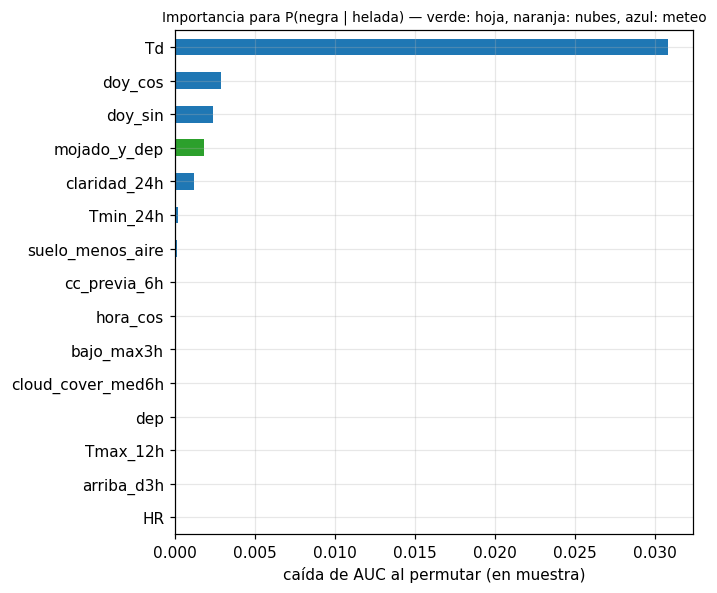

In [16]:
# ¿Qué distingue a una helada negra en el momento de la emisión? (importancia, alerta 6 h)
s = OOF_T['alerta6']
m = clf_tipo().fit(s[F_TIPO], s['y_negra'])
pi = permutation_importance(m, s[F_TIPO], s['y_negra'], scoring='roc_auc', n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=F_TIPO).sort_values().tail(15)
color = ['tab:green' if f in F_HOJA else 'tab:orange' if f in F_NUB else 'tab:blue' for f in imp.index]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
imp.plot.barh(ax=ax, color=color)
ax.set_title('Importancia para P(negra | helada) — verde: hoja, naranja: nubes, azul: meteo', fontsize=9)
ax.set_xlabel('caída de AUC al permutar (en muestra)'); plt.tight_layout(); plt.show()

## 6. Ejemplos: probabilidad de helada y de helada negra (predicciones fuera de muestra)

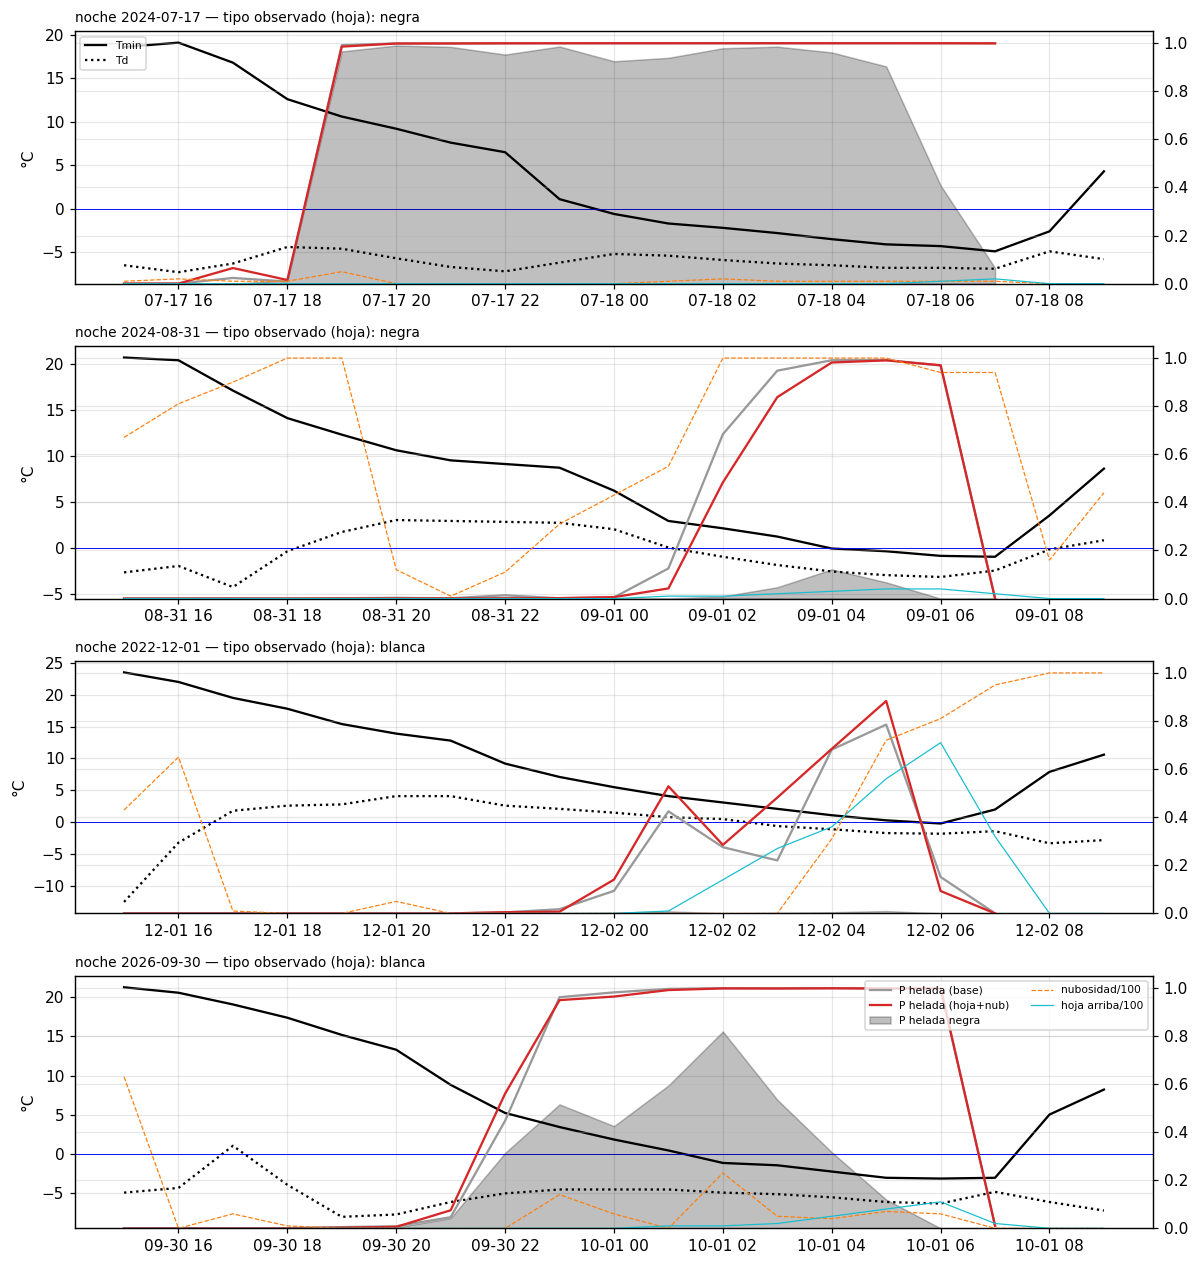

In [17]:
r6 = OOF[('meteorologica', 'alerta6')]
t6 = OOF_T['alerta6'][['p_negra']]
r6 = r6.join(t6)
r6['P_negra_total'] = r6['p_+ hoja + nubosidad'] * r6['p_negra'].fillna(0)
ej = list(NOCH[NOCH.tipo_hoja == 'negra'].sample(2, random_state=1).index) + \
     list(NOCH[NOCH.tipo_hoja == 'blanca'].sample(2, random_state=1).index)
fig, axs = plt.subplots(len(ej), 1, figsize=(11, 2.9 * len(ej)))
for ax, noche in zip(axs, ej):
    ini, fin = noche + pd.Timedelta(hours=15), noche + pd.Timedelta(hours=33)
    o = D.loc[ini:fin]
    ax.plot(o.index, o['Tmin'], 'k-', lw=1.5, label='Tmin'); ax.plot(o.index, o['Td'], 'k:', label='Td')
    ax.axhline(0, color='b', lw=.6); ax.set_ylabel('°C')
    ax2 = ax.twinx(); r = r6.loc[ini:fin]
    ax2.plot(r.index, r['p_base'], color='0.6', label='P helada (base)')
    ax2.plot(r.index, r['p_+ hoja + nubosidad'], color='tab:red', label='P helada (hoja+nub)')
    ax2.fill_between(r.index, r['P_negra_total'], color='k', alpha=.25, label='P helada negra')
    ax2.plot(o.index, NUB.reindex(o.index)['cloud_cover'] / 100, color='tab:orange', lw=.8, ls='--', label='nubosidad/100')
    ax2.plot(o.index, REL['arriba'].reindex(o.index).clip(0, 100) / 100, color='tab:cyan', lw=.8, label='hoja arriba/100')
    ax2.set_ylim(0, 1.05)
    ax.set_title(f'noche {noche:%Y-%m-%d} — tipo observado (hoja): {TIPO[noche]}', fontsize=9, loc='left')
axs[0].legend(fontsize=7, loc='upper left'); ax2.legend(fontsize=7, loc='upper right', ncol=2)
plt.tight_layout(); plt.show()

## 7. Modelo final y uso operativo

Entrenamos con todos los años:

* clasificadores de helada (0 °C y 2 °C) y regresores de Tmin con **hoja + nubosidad**, más respaldos **sin hoja** (meteo + nubosidad) y **sin nubosidad** (meteo + hoja);
* el clasificador `P(negra | helada)`.

**Cambios respecto de la primera versión** (justificados en `el_mantaro_comparacion_modelos.ipynb`):

1. Los clasificadores de helada se **calibran con Platt** (`CalibratedClassifierCV(method='sigmoid')`). La curva de calibración se ajusta con predicciones fuera de muestra **por años** (`GroupKFold`), y luego el boosting se reentrena con todos los datos (`ensemble=False`, para no multiplicar el tamaño del modelo). En la comparación, la calibración mejoró el BSS en 13 de 16 combinaciones, sobre todo a 4–6 h, sin cambiar el CSI.
2. El modelo de **tipo de helada** pasa a ser una **logística simple** con 3 variables: punto de rocío (`Td`), depresión `T − Td` (`dep`) y nubosidad media prevista de 6 h (`cloud_cover_med6h`), con pesos balanceados. En la comparación tuvo AUC 0.93 a 3 h y 0.88 en la alerta de 6 h, frente a 0.90 y 0.85 del boosting con 65 variables, y es mucho más fácil de explicar. Si falta la nubosidad, se imputa con la mediana.

Las métricas de las secciones 4 y 5 corresponden a los modelos **sin calibrar** y al boosting de tipo; las de los modelos nuevos están en el notebook de comparación.

`pronosticar(d_horario, t)` descarga la nubosidad pronosticada de la **Forecast API** de Open-Meteo (o de la Historical Forecast API si *t* es una fecha pasada) y devuelve, para cada plazo, `P_helada_0C`, `P_helada_2C`, `Tmin`, `P_negra|helada` y `P_helada_negra`.

In [18]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

def clf_platt(X, y, grupos):
    # Platt con curva ajustada fuera de muestra por años; el boosting final se entrena con todos los datos
    cv = list(GroupKFold(n_splits=grupos.nunique()).split(X, y, grupos))
    return CalibratedClassifierCV(clf(), method='sigmoid', cv=cv, ensemble=False).fit(X, y)

F_TIPO_SIMPLE = ['Td', 'dep', 'cloud_cover_med6h']
def clf_tipo_simple():
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                         LogisticRegression(class_weight='balanced', max_iter=3000))

F_SIN_HOJA = F_METEO + F_NUB
F_SIN_NUB = F_METEO + F_HOJA
F_TODO = F_METEO + F_HOJA + F_NUB
FINAL = {'version': 'v2: helada calibrada con Platt; tipo con logística simple (Td, dep, cloud_cover_med6h)',
         'umbrales': UMBRALES, 'leads': LEADS, 'p_alerta': P_ALERTA,
         'feats': {'todo': F_TODO, 'sin_hoja': F_SIN_HOJA, 'sin_nub': F_SIN_NUB, 'tipo': F_TIPO_SIMPLE},
         'clf': {}, 'reg': {}, 'tipo': {}}
for lead in [*LEADS, 'alerta6']:
    col = f'y_T_{lead}'; sub = MUESTRA[MUESTRA[col].notna()]
    for nom_u, u in UMBRALES.items():
        for k, fs in (('todo', F_TODO), ('sin_hoja', F_SIN_HOJA), ('sin_nub', F_SIN_NUB)):
            FINAL['clf'][(nom_u, lead, k)] = clf_platt(sub[fs], sub[col] <= u, sub['anio'])
    if lead != 'alerta6':
        for k, fs in (('todo', F_TODO), ('sin_hoja', F_SIN_HOJA), ('sin_nub', F_SIN_NUB)):
            FINAL['reg'][(lead, k)] = reg().fit(sub[fs], sub[col])
    s = OOF_T[lead]
    FINAL['tipo'][lead] = clf_tipo_simple().fit(s[F_TIPO_SIMPLE], s['y_negra'])
joblib.dump(FINAL, OUT / 'modelos' / 'el_mantaro_heladas_nubosidad.joblib')
print('guardado:', OUT / 'modelos' / 'el_mantaro_heladas_nubosidad.joblib')

guardado: /home/luismartin/Documentos/agro/E3/proy1/resultados/modelos/el_mantaro_heladas_nubosidad.joblib


In [19]:
URL_FC = ('https://api.open-meteo.com/v1/forecast?latitude={lat}&longitude={lon}&hourly=' + ','.join(NUB_COLS) +
          '&timezone=America%2FLima&past_days=2&forecast_days=2')

def nubosidad_openmeteo(t, lat=LAT, lon=LON):
    # Forecast API para el presente; Historical Forecast API para fechas pasadas
    t = pd.Timestamp(t)
    if t >= pd.Timestamp.now().normalize() - pd.Timedelta(days=1):
        j = json.load(urllib.request.urlopen(URL_FC.format(lat=lat, lon=lon), timeout=60))
        df = pd.DataFrame(j['hourly']).rename(columns={'time': 'fecha'})
        df['fecha'] = pd.to_datetime(df['fecha'])
        return df.set_index('fecha')
    return descargar_nubosidad_hist((t - pd.Timedelta(days=2)).date(), (t + pd.Timedelta(days=1)).date(), lat, lon)

def pronosticar(d_horario, t, nub=None, modelo=FINAL):
    # d_horario: CSV horario de la estación (formato data/processed/horario) con >= 60 días previos a t
    #   (claridad_24h usa una ventana de 60 días; la línea base de la hoja, 30). Lo más simple: pasar el CSV completo.
    t = pd.Timestamp(t)
    d = preparar(d_horario)
    nub = nubosidad_openmeteo(t) if nub is None else nub
    X = var_meteo(d).join(var_hoja(d))
    X = X.reindex(X.index.union(nub.index)).join(var_nub(nub, X.index.union(nub.index)))
    hoja_ok = X.loc[t, ['arriba_rel', 'bajo_rel']].notna().all()
    nub_ok = pd.notna(X.loc[t, 'cloud_cover_med6h'])
    k = 'todo' if hoja_ok and nub_ok else ('sin_hoja' if nub_ok else 'sin_nub')
    filas = []
    for lead in [*modelo['leads'], 'alerta6']:
        x = X.loc[[t], modelo['feats'][k]]
        p0 = float(modelo['clf'][('meteorologica', lead, k)].predict_proba(x)[0, 1])
        p2 = float(modelo['clf'][('agronomica', lead, k)].predict_proba(x)[0, 1])
        pn = float(modelo['tipo'][lead].predict_proba(X.loc[[t], modelo['feats']['tipo']])[0, 1])
        filas.append({'plazo': lead, 'hora_objetivo': t + pd.Timedelta(hours=6 if lead == 'alerta6' else lead),
                      'variante': k, 'P_helada_0C': round(p0, 3), 'P_helada_2C': round(p2, 3),
                      'Tmin_pron': round(float(modelo['reg'][(lead, k)].predict(x)[0]), 1) if lead != 'alerta6' else np.nan,
                      'P_negra|helada': round(pn, 3), 'P_helada_negra': round(p0 * pn, 3)})
    out = pd.DataFrame(filas)
    out['alerta'] = np.select([out['P_helada_0C'] >= modelo['p_alerta'], out['P_helada_2C'] >= modelo['p_alerta']],
                              ['HELADA', 'helada agronómica'], '')
    out.loc[(out['alerta'] == 'HELADA') & (out['P_negra|helada'] >= 0.5), 'alerta'] = 'HELADA NEGRA'
    return out

# Ejemplo con una noche de helada negra del registro (usa la nubosidad ya descargada)
raw = pd.read_csv(DATA / 'horario' / f'{EST}.csv', parse_dates=['fecha'])
noche_ej = NOCH[NOCH.tipo_hoja == 'negra'].index[-1]
t_ej = noche_ej + pd.Timedelta(hours=22)
print('emisión', t_ej, '| tipo observado:', TIPO[noche_ej], '| Tmin observada', NOCH.loc[noche_ej, 'tmin'])
pronosticar(raw, t_ej, nub=NUB)

emisión 2025-12-06 22:00:00 | tipo observado: negra | Tmin observada -1.1


,plazo,hora_objetivo,variante,P_helada_0C,P_helada_2C,Tmin_pron,P_negra|helada,P_helada_negra,alerta
0,1,2025-12-06 23:00:00,todo,0.000,0.004,4.7,1.000,0.000,
1,2,2025-12-07 00:00:00,todo,0.005,0.052,3.3,0.997,0.005,
2,3,2025-12-07 01:00:00,todo,0.051,0.350,2.4,0.978,0.050,
3,4,2025-12-07 02:00:00,todo,0.077,0.858,1.0,0.922,0.071,helada agronómica
4,5,2025-12-07 03:00:00,todo,0.224,0.930,-0.0,0.876,0.196,helada agronómica
5,6,2025-12-07 04:00:00,todo,0.937,0.975,-0.4,0.845,0.792,HELADA NEGRA
6,alerta6,2025-12-07 04:00:00,todo,0.931,0.974,NaN,0.837,0.779,HELADA NEGRA


## 8. Conclusiones y advertencias

* **Nubosidad**: compara las variantes `+ nubosidad` y `base` en las tablas de la sección 4.1. Si el intervalo del ΔBSS / ΔCSI queda por encima de 0, la mejora es significativa.
* **Tipo de helada**: el sensor de hoja da una **etiqueta observada** de helada blanca o negra que no existía en la estación. El modelo de la sección 5 trata de anticiparla; en el modelo final se reemplazó por una logística simple de 3 variables, que en `el_mantaro_comparacion_modelos.ipynb` resultó igual o mejor. Las heladas negras son **pocas** (unas decenas de noches), así que sus métricas tienen intervalos amplios y conviene revisarlas cuando haya más temporadas.
* La evaluación de la nubosidad es **ligeramente optimista**, porque el archivo de pronósticos usa las corridas más recientes. En operación, la nubosidad a 4–6 h vendrá de una corrida algo más antigua.
* Para operar el modelo cada noche hacen falta los datos horarios de la estación casi en tiempo real, con al menos 60 días previos (60 para la claridad de la radiación y 30 para la línea base de la hoja), y acceso a internet para Open-Meteo.
* **Calibración**: el modelo final calibra con Platt las probabilidades de helada; cuando dice 30 %, la helada ocurre cerca del 30 % de las veces (ver `el_mantaro_comparacion_modelos.ipynb`, sección 6).